# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Zico Diego Rio Ramadhonny | 5054251023 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [55]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).

import os
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm
import seaborn as sns
import torch.nn as nn
import kagglehub as kg
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_curve, confusion_matrix, roc_auc_score

torch.manual_seed(42)
np.random.seed(42)

In [56]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

path = kg.dataset_download("shrutimechlearn/churn-modelling")
print("Path to dataset files:", path)

dataset_file = None
files_in_path = [os.path.join(path, file) for file in os.listdir(path)]
for file in files_in_path:
    if os.path.isfile(file) and os.path.splitext(os.path.basename(file))[-1] == ".csv":
        dataset_file = file
        break
    
if dataset_file is None:
    raise FileNotFoundError(f"CSV dataset file can't be found at {path}.")

#  Load Dataset dan menampilkan informasi dasar tentang dataset, seperti jumlah baris dan kolom, tipe data, jumlah nilai yang hilang, dan informasi lainnya yang dibutuhkan.
data = pd.read_csv(dataset_file)
print("Shape:", data.shape)
display(data.info())
display(data.describe())
display(data.isna().sum())

Path to dataset files: /home/zico/.cache/kagglehub/datasets/shrutimechlearn/churn-modelling/versions/1
Shape: (10000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory u

None

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Exited
0    7963
1    2037
Name: count, dtype: int64

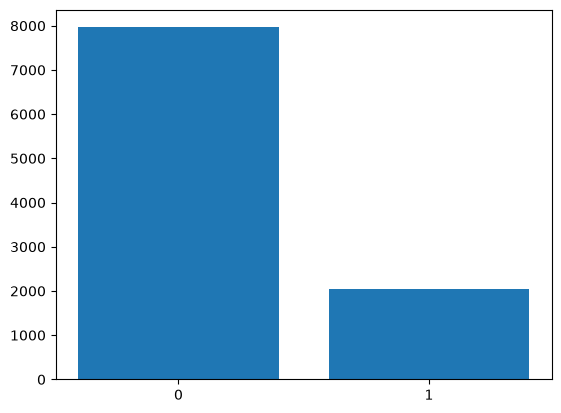

In [57]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
target_count = data["Exited"].value_counts()
display(target_count)

plt.bar(target_count.index, target_count.values, 0.8)
plt.xticks([0, 1])
plt.show()

array([[<Axes: title={'center': 'RowNumber'}>,
        <Axes: title={'center': 'CustomerId'}>,
        <Axes: title={'center': 'CreditScore'}>],
       [<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Tenure'}>,
        <Axes: title={'center': 'Balance'}>],
       [<Axes: title={'center': 'NumOfProducts'}>,
        <Axes: title={'center': 'HasCrCard'}>,
        <Axes: title={'center': 'IsActiveMember'}>],
       [<Axes: title={'center': 'EstimatedSalary'}>, <Axes: >, <Axes: >]],
      dtype=object)

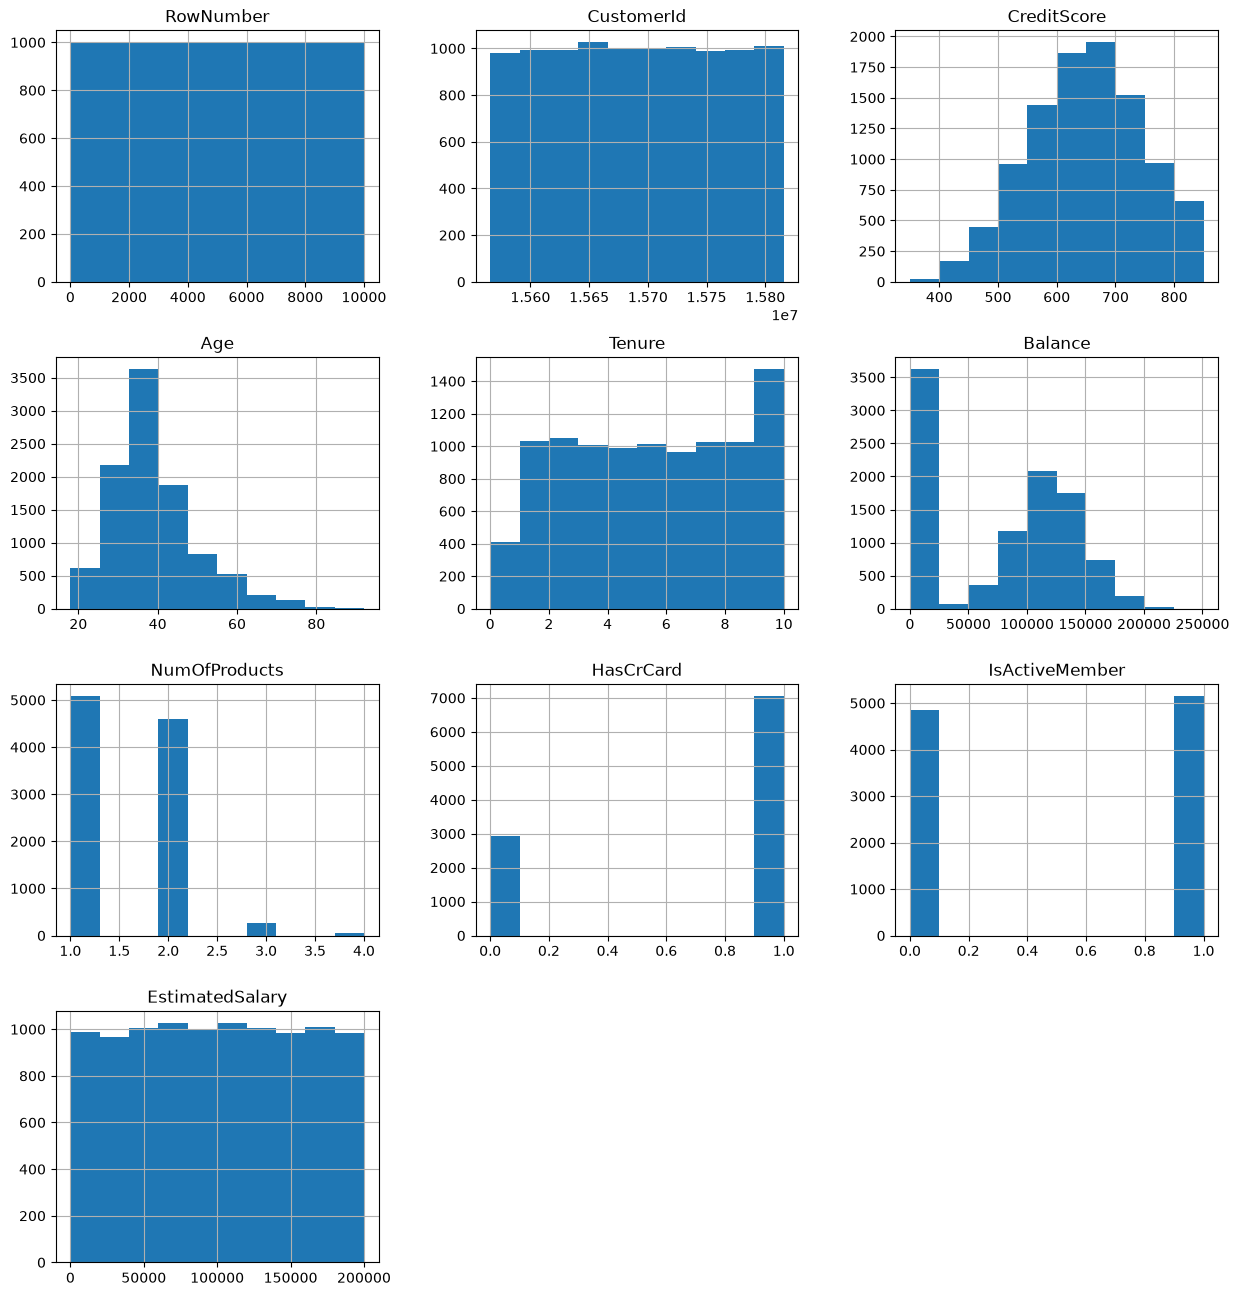

In [58]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.
not_target = data.drop(columns=["Exited"])
not_target.hist(figsize=(15, 16))

In [59]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).
cat_cols_for_proportion = ("Geography", "Gender", "IsActiveMember", "NumOfProducts")
for col in cat_cols_for_proportion:
    display(data[col].value_counts(normalize=True))

Geography
France     0.5014
Germany    0.2509
Spain      0.2477
Name: proportion, dtype: float64

Gender
Male      0.5457
Female    0.4543
Name: proportion, dtype: float64

IsActiveMember
1    0.5151
0    0.4849
Name: proportion, dtype: float64

NumOfProducts
1    0.5084
2    0.4590
3    0.0266
4    0.0060
Name: proportion, dtype: float64

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [60]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

to_drop = ["RowNumber", "CustomerId", "Surname"]
# RowNumber: representasi baris dalam data
# CustomerId: unique identifier
# Surname: nama akhir (nama tidak memiliki hubungan  dengan churn)

data = data.drop(columns=to_drop)
data["Gender"] = data["Gender"].map(lambda x: 0 if x == "Male" else 1)
display(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  int64  
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(8), str(1)
memory usage: 859.5 KB


None

In [61]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

train_count = int(len(data) * 0.7)
val_test_count = int((len(data) - train_count) // 2)

X_train_val, X_test, y_train_val, y_test = train_test_split(
    data.drop(columns=["Exited"]), data["Exited"], stratify=data["Exited"], 
    test_size=val_test_count, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, stratify=y_train_val, 
    test_size=val_test_count, random_state=42
)

print("Train shape:", X_train.shape)
print("Val shape:", X_val.shape)
print("Test shape:", X_test.shape)
display(X_train.head())

Train shape: (7000, 10)
Val shape: (1500, 10)
Test shape: (1500, 10)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
7036,540,Germany,0,37,3,129965.18,1,0,0,19374.08
9196,794,Spain,1,37,9,0.00,2,1,0,68008.85
8742,693,Spain,1,45,4,0.00,2,1,1,26589.56
5496,620,France,1,42,1,0.00,2,0,1,65565.92
4225,648,Spain,0,36,8,146943.38,2,1,1,130041.45


In [62]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

scaler = StandardScaler()

val_id = train_count - 1
test_id = train_count + val_test_count - 1

concat_X = pd.concat([X_train, X_val, X_test])
X_dummies = pd.get_dummies(concat_X, columns=["Geography"]).reset_index(drop=True)

X_train = X_dummies.loc[:val_id]
X_val = X_dummies.loc[val_id+1:test_id]
X_test = X_dummies[test_id+1:]

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print(X_train[:5, :], X_train.shape)

[[-1.15309804 -0.90740923 -0.18184592 -0.69263044  0.86224807 -0.90668108
  -1.56523971 -1.02869732 -1.39945431 -0.99146499  1.71830416 -0.57932976]
 [ 1.47312503  1.1020386  -0.18184592  1.38496407 -1.22778622  0.81237839
   0.63887978 -1.02869732 -0.5525995  -0.99146499 -0.58196914  1.72613262]
 [ 0.42883948  1.1020386   0.58238458 -0.34636468 -1.22778622  0.81237839
   0.63887978  0.97210324 -1.27381449 -0.99146499 -0.58196914  1.72613262]
 [-0.32594117  1.1020386   0.29579814 -1.38516194 -1.22778622  0.81237839
  -1.56523971  0.97210324 -0.59513711  1.00860848 -0.58196914 -0.57932976]
 [-0.03643626 -0.90740923 -0.27737473  1.03869832  1.1352829   0.81237839
   0.63887978  0.97210324  0.52754556 -0.99146499 -0.58196914  1.72613262]] (7000, 12)


In [63]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

X_train_tensor = torch.from_numpy(X_train)
X_val_tensor = torch.from_numpy(X_val)
X_test_tensor = torch.from_numpy(X_test)

y_train_tensor = torch.from_numpy(y_train.to_numpy()).unsqueeze(1).to(torch.float32)
y_val_tensor = torch.from_numpy(y_val.to_numpy()).unsqueeze(1).to(torch.float32)
y_test_tensor = torch.from_numpy(y_test.to_numpy()).unsqueeze(1).to(torch.float32)

# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [64]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

logreg = LogisticRegression().fit(X_train, y_train)
logreg_pred = logreg.predict(X_test)
logreg_prob = logreg.predict_proba(X_test)

## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [65]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).

class ANN(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.ann = nn.Sequential(
            nn.Linear(in_channels, int(abs(out_channels - in_channels) // 2)),
            nn.ReLU(),
            nn.Linear(int(abs(out_channels - in_channels) // 2), out_channels)
        )
        
    def forward(self, x):
        return self.ann(x)
    
class ChurnDataset(torch.utils.data.Dataset):
    def __init__(self, x, y):
        super().__init__()
        self.x = x
        self.y = y
        
    def __len__(self):
        return len(self.x)
    
    def __getitem__(self, idx):
        return self.x[idx, :], self.y[idx, :] 

In [66]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.

LR = 1e-4
EPOCHS = 100
BATCH_SIZE = 100

ann_model = ANN(12, 1)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(ann_model.parameters(), lr=LR)

train_dataloader = torch.utils.data.DataLoader(
    ChurnDataset(X_train_tensor, y_train_tensor), shuffle=True, batch_size=BATCH_SIZE
)
val_dataloader = torch.utils.data.DataLoader(
    ChurnDataset(X_val_tensor, y_val_tensor), shuffle=False, batch_size=BATCH_SIZE
)
test_dataloader = torch.utils.data.DataLoader(
    ChurnDataset(X_test_tensor, y_test_tensor), shuffle=False, batch_size=BATCH_SIZE
)

print("Jumlah parameter:", sum(p.numel() for p in ann_model.parameters() if p.requires_grad))

res_dict = dict()
for epoch in range(EPOCHS):
    curr_res = dict()
    
    ann_model.train()
    total_train_loss = 0.0
    total_correct = 0
    total_samples = 0
    
    train_instance = tqdm(train_dataloader, desc=f"Training... [{epoch+1}/ {EPOCHS}]")
    for x, y in train_instance:
        x = x.float()
        y = y.float()  # Ensure target is also float if using BCEWithLogitsLoss / MSE
        optimizer.zero_grad()
        
        output = ann_model(x)
        train_loss = loss_fn(output, y)
        
        train_loss.backward()
        optimizer.step()
        
        # Accumulate loss sum
        total_train_loss += train_loss.item() * x.size(0)
        
        # Correct accuracy accumulation
        preds = (torch.sigmoid(output.squeeze(1)) > 0.5)
        targets = y.squeeze(1)
        total_correct += (preds == targets).sum().item()
        total_samples += x.size(0)
        
    epoch_loss = total_train_loss / total_samples
    epoch_acc = total_correct / total_samples
    
    curr_res["train_loss"] = epoch_loss
    curr_res["train_acc"] = epoch_acc
    
    print(f"Training... [{epoch+1}/{EPOCHS}], loss: {epoch_loss:.4f}, acc: {epoch_acc:.4f}")
    
    ann_model.eval()
    total_val_loss = 0.0
    total_correct = 0
    total_samples = 0
    
    val_instance = tqdm(val_dataloader, desc=f"Validating... [{epoch+1}/{EPOCHS}]")
    with torch.no_grad():
        for x, y in val_instance:
            x = x.float()
            y = y.float()
        
            output = ann_model(x)
            val_loss = loss_fn(output, y)
        
            # Accumulate loss sum
            total_val_loss += val_loss.item() * x.size(0)
        
            # Correct accuracy accumulation
            preds = (torch.sigmoid(output.squeeze(1)) > 0.5)
            targets = y.squeeze(1)
            total_correct += (preds == targets).sum().item()
            total_samples += x.size(0)
    
    epoch_loss = total_val_loss / total_samples
    epoch_acc = total_correct / total_samples
    
    curr_res["val_loss"] = epoch_loss
    curr_res["val_acc"] = epoch_acc
    
    print(f"Validating... [{epoch+1}/{EPOCHS}], loss: {epoch_loss:.4f}, acc: {epoch_acc:.4f}\n")
    
    res_dict[epoch] = curr_res

Jumlah parameter: 71


Training... [1/ 100]:   0%|          | 0/70 [00:00<?, ?it/s]

Training... [1/ 100]: 100%|██████████| 70/70 [00:00<00:00, 1329.73it/s]


Training... [1/100], loss: 0.7585, acc: 0.2989


Validating... [1/100]: 100%|██████████| 15/15 [00:00<00:00, 2826.60it/s]


Validating... [1/100], loss: 0.7570, acc: 0.2933



... (392 outputs left out)

Training... [100/ 100]: 100%|██████████| 70/70 [00:00<00:00, 1465.45it/s]


Training... [100/100], loss: 0.4189, acc: 0.8131


Validating... [100/100]: 100%|██████████| 15/15 [00:00<00:00, 2339.09it/s]

Validating... [100/100], loss: 0.4238, acc: 0.8113



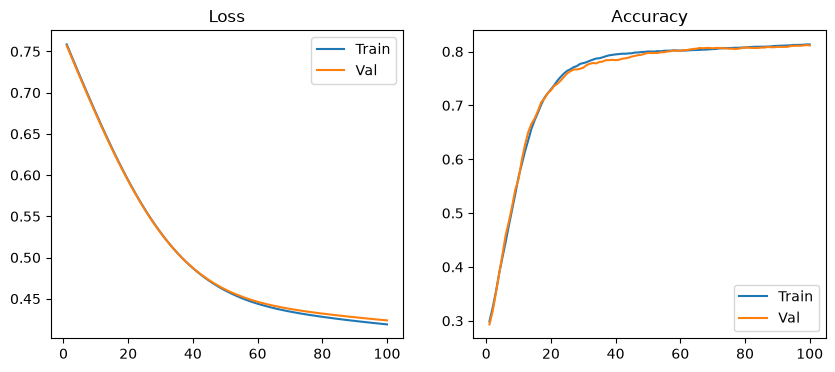

In [67]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

all_train_loss = [epoch["train_loss"] for _, epoch in res_dict.items()]
all_val_loss = [epoch["val_loss"] for _, epoch in res_dict.items()]

all_train_acc = [epoch["train_acc"] for _, epoch in res_dict.items()]
all_val_acc = [epoch["val_acc"] for _, epoch in res_dict.items()]

ax[0].plot(range(1, EPOCHS+1), all_train_loss, label="Train")
ax[0].plot(range(1, EPOCHS+1), all_val_loss, label="Val")
ax[0].set_title("Loss")
ax[0].legend()

ax[1].plot(range(1, EPOCHS+1), all_train_acc, label="Train")
ax[1].plot(range(1, EPOCHS+1), all_val_acc, label="Val")
ax[1].set_title("Accuracy")
ax[1].legend()

plt.show()

In [68]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.

test_pred = []
test_prob = []
for epoch in range(1):
    ann_model.eval()
    total_val_loss = 0.0
    total_correct = 0
    total_samples = 0
    
    test_instance = tqdm(test_dataloader, desc=f"Testing... [{epoch+1}/{EPOCHS}]")
    with torch.no_grad():
        for x, y in test_instance:
            x = x.float()
            y = y.float()
        
            output = ann_model(x)
            val_loss = loss_fn(output, y)
        
            # Accumulate loss sum
            total_val_loss += val_loss.item() * x.size(0)
        
            # Correct accuracy accumulation
            preds = (torch.sigmoid(output.squeeze(1)) > 0.5)
            targets = y.squeeze(1)
            total_correct += (preds == targets).sum().item()
            total_samples += x.size(0)
            
            test_pred += preds.detach().tolist()
            test_prob += torch.sigmoid(output.squeeze(1)).detach().tolist()
    
    epoch_loss = total_val_loss / total_samples
    epoch_acc = total_correct / total_samples
    
    print(f"Testing... [{epoch+1}/{EPOCHS}], loss: {epoch_loss:.4f}, acc: {epoch_acc:.4f}\n")

Testing... [1/100]: 100%|██████████| 15/15 [00:00<00:00, 2185.37it/s]

Testing... [1/100], loss: 0.4299, acc: 0.8087



## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [69]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

class ANNDeep(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.ann = nn.Sequential(
            nn.Linear(in_channels, 2 + int(abs(out_channels - in_channels) // 2)),
            nn.ReLU(),
            nn.Dropout(0.05),
            nn.Linear(2 + int(abs(out_channels - in_channels) // 2), int(abs(out_channels - in_channels) // 2)),
            nn.ReLU(),
            nn.Dropout(0.05),
            nn.Linear(int(abs(out_channels - in_channels) // 2), abs(int(abs(out_channels - in_channels) // 2) - 2)),
            nn.ReLU(),
            nn.Dropout(0.05),
            nn.Linear(abs(int(abs(out_channels - in_channels) // 2) - 2), out_channels)
        )
        
    def forward(self, x):
        return self.ann(x)

Jumlah parameter: 153


Training... [1/ 100]: 100%|██████████| 70/70 [00:00<00:00, 1064.66it/s]


Training... [1/100], loss: 0.6329, acc: 0.7963


Validating... [1/100]: 100%|██████████| 15/15 [00:00<00:00, 2095.75it/s]


Validating... [1/100], loss: 0.6286, acc: 0.7967



Training... [2/ 100]: 100%|██████████| 70/70 [00:00<00:00, 1207.72it/s]


... (391 outputs left out)

Training... [100/ 100]: 100%|██████████| 70/70 [00:00<00:00, 1272.36it/s]


Training... [100/100], loss: 0.4374, acc: 0.7963


Validating... [100/100]: 100%|██████████| 15/15 [00:00<00:00, 2059.19it/s]


Validating... [100/100], loss: 0.4397, acc: 0.7967



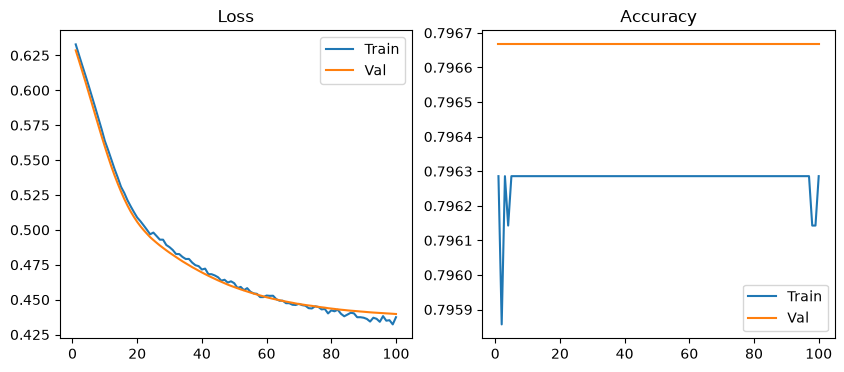

In [70]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

LR = 1e-4
EPOCHS = 100
BATCH_SIZE = 100

ann_model = ANNDeep(12, 1)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(ann_model.parameters(), lr=LR)

train_dataloader = torch.utils.data.DataLoader(
    ChurnDataset(X_train_tensor, y_train_tensor), shuffle=True, batch_size=BATCH_SIZE
)
val_dataloader = torch.utils.data.DataLoader(
    ChurnDataset(X_val_tensor, y_val_tensor), shuffle=False, batch_size=BATCH_SIZE
)
test_dataloader = torch.utils.data.DataLoader(
    ChurnDataset(X_test_tensor, y_test_tensor), shuffle=False, batch_size=BATCH_SIZE
)

print("Jumlah parameter:", sum(p.numel() for p in ann_model.parameters() if p.requires_grad))

res_dict = dict()
for epoch in range(EPOCHS):
    curr_res = dict()
    
    ann_model.train()
    total_train_loss = 0.0
    total_correct = 0
    total_samples = 0
    
    train_instance = tqdm(train_dataloader, desc=f"Training... [{epoch+1}/ {EPOCHS}]")
    for x, y in train_instance:
        x = x.float()
        y = y.float()  # Ensure target is also float if using BCEWithLogitsLoss / MSE
        optimizer.zero_grad()
        
        output = ann_model(x)
        train_loss = loss_fn(output, y)
        
        train_loss.backward()
        optimizer.step()
        
        # Accumulate loss sum
        total_train_loss += train_loss.item() * x.size(0)
        
        # Correct accuracy accumulation
        preds = (torch.sigmoid(output.squeeze(1)) > 0.5)
        targets = y.squeeze(1)
        total_correct += (preds == targets).sum().item()
        total_samples += x.size(0)
        
    epoch_loss = total_train_loss / total_samples
    epoch_acc = total_correct / total_samples
    
    curr_res["train_loss"] = epoch_loss
    curr_res["train_acc"] = epoch_acc
    
    print(f"Training... [{epoch+1}/{EPOCHS}], loss: {epoch_loss:.4f}, acc: {epoch_acc:.4f}")
    
    ann_model.eval()
    total_val_loss = 0.0
    total_correct = 0
    total_samples = 0
    
    val_instance = tqdm(val_dataloader, desc=f"Validating... [{epoch+1}/{EPOCHS}]")
    with torch.no_grad():
        for x, y in val_instance:
            x = x.float()
            y = y.float()
        
            output = ann_model(x)
            val_loss = loss_fn(output, y)
        
            # Accumulate loss sum
            total_val_loss += val_loss.item() * x.size(0)
        
            # Correct accuracy accumulation
            preds = (torch.sigmoid(output.squeeze(1)) > 0.5)
            targets = y.squeeze(1)
            total_correct += (preds == targets).sum().item()
            total_samples += x.size(0)
    
    epoch_loss = total_val_loss / total_samples
    epoch_acc = total_correct / total_samples
    
    curr_res["val_loss"] = epoch_loss
    curr_res["val_acc"] = epoch_acc
    
    print(f"Validating... [{epoch+1}/{EPOCHS}], loss: {epoch_loss:.4f}, acc: {epoch_acc:.4f}\n")
    
    res_dict[epoch] = curr_res
    
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

all_train_loss = [epoch["train_loss"] for _, epoch in res_dict.items()]
all_val_loss = [epoch["val_loss"] for _, epoch in res_dict.items()]

all_train_acc = [epoch["train_acc"] for _, epoch in res_dict.items()]
all_val_acc = [epoch["val_acc"] for _, epoch in res_dict.items()]

ax[0].plot(range(1, EPOCHS+1), all_train_loss, label="Train")
ax[0].plot(range(1, EPOCHS+1), all_val_loss, label="Val")
ax[0].set_title("Loss")
ax[0].legend()

ax[1].plot(range(1, EPOCHS+1), all_train_acc, label="Train")
ax[1].plot(range(1, EPOCHS+1), all_val_acc, label="Val")
ax[1].set_title("Accuracy")
ax[1].legend()

plt.show()

In [71]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

test_pred_dropout = []
test_prob_dropout = []
for epoch in range(1):
    ann_model.eval()
    total_val_loss = 0.0
    total_correct = 0
    total_samples = 0
    
    test_instance = tqdm(test_dataloader, desc=f"Testing... [{epoch+1}/{EPOCHS}]")
    with torch.no_grad():
        for x, y in test_instance:
            x = x.float()
            y = y.float()
        
            output = ann_model(x)
            val_loss = loss_fn(output, y)
        
            # Accumulate loss sum
            total_val_loss += val_loss.item() * x.size(0)
        
            # Correct accuracy accumulation
            preds = (torch.sigmoid(output.squeeze(1)) > 0.5)
            targets = y.squeeze(1)
            total_correct += (preds == targets).sum().item()
            total_samples += x.size(0)
            
            test_pred_dropout += preds.detach().tolist()
            test_prob_dropout += torch.sigmoid(output.squeeze(1)).detach().tolist()
    
    epoch_loss = total_val_loss / total_samples
    epoch_acc = total_correct / total_samples
    
    print(f"Testing... [{epoch+1}/{EPOCHS}], loss: {epoch_loss:.4f}, acc: {epoch_acc:.4f}\n")

Testing... [1/100]: 100%|██████████| 15/15 [00:00<00:00, 1327.28it/s]

Testing... [1/100], loss: 0.4360, acc: 0.7960



## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [72]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

LR = 1e-4
EPOCHS = 100
BATCH_SIZE = 100

ann_model = ANNDeep(12, 1)
y_train_count = y_train.value_counts()

loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(y_train_count[0]/y_train_count[1]))
optimizer = optim.Adam(ann_model.parameters(), lr=LR)

train_dataloader = torch.utils.data.DataLoader(
    ChurnDataset(X_train_tensor, y_train_tensor), shuffle=True, batch_size=BATCH_SIZE
)
val_dataloader = torch.utils.data.DataLoader(
    ChurnDataset(X_val_tensor, y_val_tensor), shuffle=False, batch_size=BATCH_SIZE
)
test_dataloader = torch.utils.data.DataLoader(
    ChurnDataset(X_test_tensor, y_test_tensor), shuffle=False, batch_size=BATCH_SIZE
)

print("Jumlah parameter:", sum(p.numel() for p in ann_model.parameters() if p.requires_grad))

res_dict = dict()
for epoch in range(EPOCHS):
    curr_res = dict()
    
    ann_model.train()
    total_train_loss = 0.0
    total_correct = 0
    total_samples = 0
    
    train_instance = tqdm(train_dataloader, desc=f"Training... [{epoch+1}/ {EPOCHS}]")
    for x, y in train_instance:
        x = x.float()
        y = y.float()  # Ensure target is also float if using BCEWithLogitsLoss / MSE
        optimizer.zero_grad()
        
        output = ann_model(x)
        train_loss = loss_fn(output, y)
        
        train_loss.backward()
        optimizer.step()
        
        # Accumulate loss sum
        total_train_loss += train_loss.item() * x.size(0)
        
        # Correct accuracy accumulation
        preds = (torch.sigmoid(output.squeeze(1)) > 0.5)
        targets = y.squeeze(1)
        total_correct += (preds == targets).sum().item()
        total_samples += x.size(0)
        
    epoch_loss = total_train_loss / total_samples
    epoch_acc = total_correct / total_samples
    
    curr_res["train_loss"] = epoch_loss
    curr_res["train_acc"] = epoch_acc
    
    print(f"Training... [{epoch+1}/{EPOCHS}], loss: {epoch_loss:.4f}, acc: {epoch_acc:.4f}")
    
    ann_model.eval()
    total_val_loss = 0.0
    total_correct = 0
    total_samples = 0
    
    val_instance = tqdm(val_dataloader, desc=f"Validating... [{epoch+1}/{EPOCHS}]")
    with torch.no_grad():
        for x, y in val_instance:
            x = x.float()
            y = y.float()
        
            output = ann_model(x)
            val_loss = loss_fn(output, y)
        
            # Accumulate loss sum
            total_val_loss += val_loss.item() * x.size(0)
        
            # Correct accuracy accumulation
            preds = (torch.sigmoid(output.squeeze(1)) > 0.5)
            targets = y.squeeze(1)
            total_correct += (preds == targets).sum().item()
            total_samples += x.size(0)
    
    epoch_loss = total_val_loss / total_samples
    epoch_acc = total_correct / total_samples
    
    curr_res["val_loss"] = epoch_loss
    curr_res["val_acc"] = epoch_acc
    
    print(f"Validating... [{epoch+1}/{EPOCHS}], loss: {epoch_loss:.4f}, acc: {epoch_acc:.4f}\n")
    
    res_dict[epoch] = curr_res

Jumlah parameter: 153


Training... [1/ 100]: 100%|██████████| 70/70 [00:00<00:00, 1137.94it/s]


Training... [1/100], loss: 1.1514, acc: 0.7963


Validating... [1/100]: 100%|██████████| 15/15 [00:00<00:00, 2264.99it/s]


Validating... [1/100], loss: 1.1482, acc: 0.7967



Training... [2/ 100]: 100%|██████████| 70/70 [00:00<00:00, 1258.51it/s]


... (391 outputs left out)

Training... [100/ 100]: 100%|██████████| 70/70 [00:00<00:00, 945.44it/s]


Training... [100/100], loss: 0.8716, acc: 0.7650


Validating... [100/100]: 100%|██████████| 15/15 [00:00<00:00, 1737.44it/s]

Validating... [100/100], loss: 0.8445, acc: 0.7687



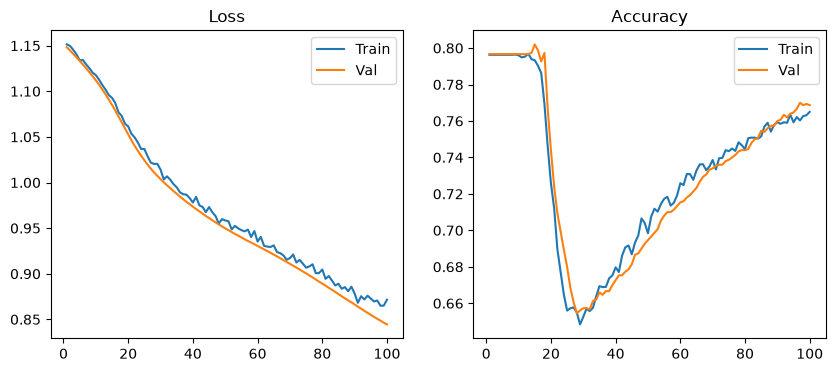

Testing... [1/100]: 100%|██████████| 15/15 [00:00<00:00, 2331.64it/s]

Testing... [1/100], loss: 0.8535, acc: 0.7607



In [73]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

all_train_loss = [epoch["train_loss"] for _, epoch in res_dict.items()]
all_val_loss = [epoch["val_loss"] for _, epoch in res_dict.items()]

all_train_acc = [epoch["train_acc"] for _, epoch in res_dict.items()]
all_val_acc = [epoch["val_acc"] for _, epoch in res_dict.items()]

ax[0].plot(range(1, EPOCHS+1), all_train_loss, label="Train")
ax[0].plot(range(1, EPOCHS+1), all_val_loss, label="Val")
ax[0].set_title("Loss")
ax[0].legend()

ax[1].plot(range(1, EPOCHS+1), all_train_acc, label="Train")
ax[1].plot(range(1, EPOCHS+1), all_val_acc, label="Val")
ax[1].set_title("Accuracy")
ax[1].legend()

plt.show()

test_pred_imbalanced = []
test_prob_imbalanced = []
for epoch in range(1):
    ann_model.eval()
    total_val_loss = 0.0
    total_correct = 0
    total_samples = 0
    
    test_instance = tqdm(test_dataloader, desc=f"Testing... [{epoch+1}/{EPOCHS}]")
    with torch.no_grad():
        for x, y in test_instance:
            x = x.float()
            y = y.float()
        
            output = ann_model(x)
            val_loss = loss_fn(output, y)
        
            # Accumulate loss sum
            total_val_loss += val_loss.item() * x.size(0)
        
            # Correct accuracy accumulation
            preds = (torch.sigmoid(output.squeeze(1)) > 0.5)
            targets = y.squeeze(1)
            total_correct += (preds == targets).sum().item()
            total_samples += x.size(0)
            
            test_pred_imbalanced += preds.detach().tolist()
            test_prob_imbalanced += torch.sigmoid(output.squeeze(1)).detach().tolist()
    
    epoch_loss = total_val_loss / total_samples
    epoch_acc = total_correct / total_samples
    
    print(f"Testing... [{epoch+1}/{EPOCHS}], loss: {epoch_loss:.4f}, acc: {epoch_acc:.4f}\n")

# 4. Evaluasi Model

In [ ]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

model_names = ["LogisticRegression", "ANN", "Deep ANN with Dropout", "Deep ANN with Dropout and Weighted BCELoss"]

logreg_report = classification_report(y_test, logreg_pred, output_dict=True)
reg_ann_report = classification_report(y_test, test_pred, output_dict=True)
deep_ann_report = classification_report(y_test, test_pred_dropout, output_dict=True)
imb_ann_report = classification_report(y_test, test_pred_imbalanced, output_dict=True)

evaluation_dict = {
    "Model": [], "Precision": [], "Recall": [], "F1-score":- [], "Accuracy": []
}
for model_name, report in zip(
    model_names,
    [logreg_report, reg_ann_report, deep_ann_report, imb_ann_report]
):
    evaluation_dict["Recall"].append(report["macro avg"]["recall"])
    evaluation_dict["Precision"].append(report["macro avg"]["precision"])
    evaluation_dict["F1-score"].append(report["macro avg"]["f1-score"])
    evaluation_dict["Accuracy"].append(report["accuracy"])
    evaluation_dict["Model"].append(model_name)
    
evaluation_df = pd.DataFrame(evaluation_dict)
display(evaluation_df)

/home/zico/miniconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/zico/miniconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/zico/miniconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Model,Precision,Recall,F1-score,Accuracy
0,LogisticRegression,0.683632,0.581962,0.593490,0.802667
1,ANN,0.723968,0.563857,0.566622,0.808667
2,Deep ANN with Dropout,0.398000,0.500000,0.443207,0.796000
3,Deep ANN with Dropout and Weighted BCELoss,0.681988,0.748801,0.695242,0.760667


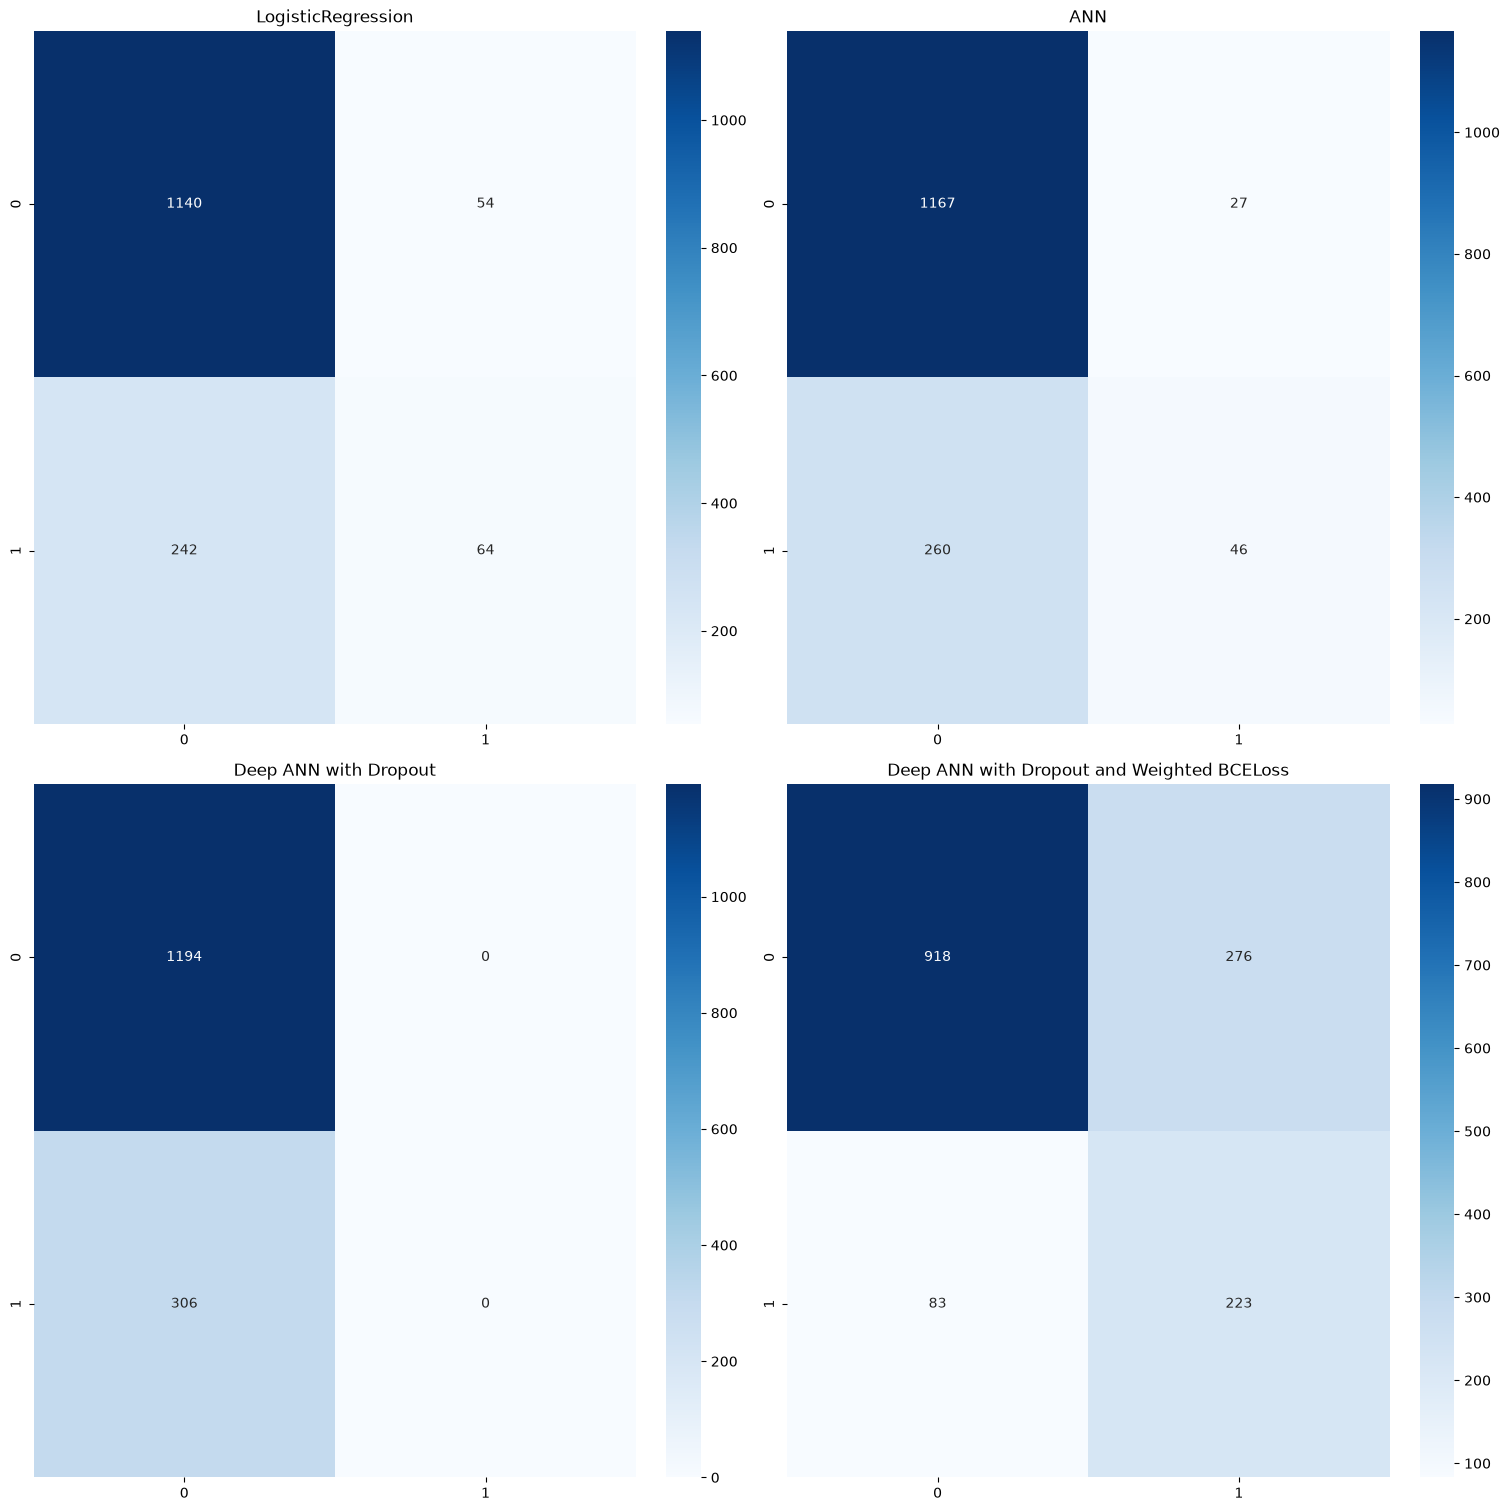

In [77]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(15, 15), layout="constrained")
ax = ax.flatten()

for i, (model_name, pred_output) in enumerate(zip(
    model_names, [logreg_pred, test_pred, test_pred_dropout, test_pred_imbalanced]
)):
    conf_mat = confusion_matrix(y_test, pred_output)
    sns.heatmap(conf_mat, annot=True, ax=ax[i], fmt="d", cmap="Blues")
    ax[i].set_title(model_name)
    
plt.show()

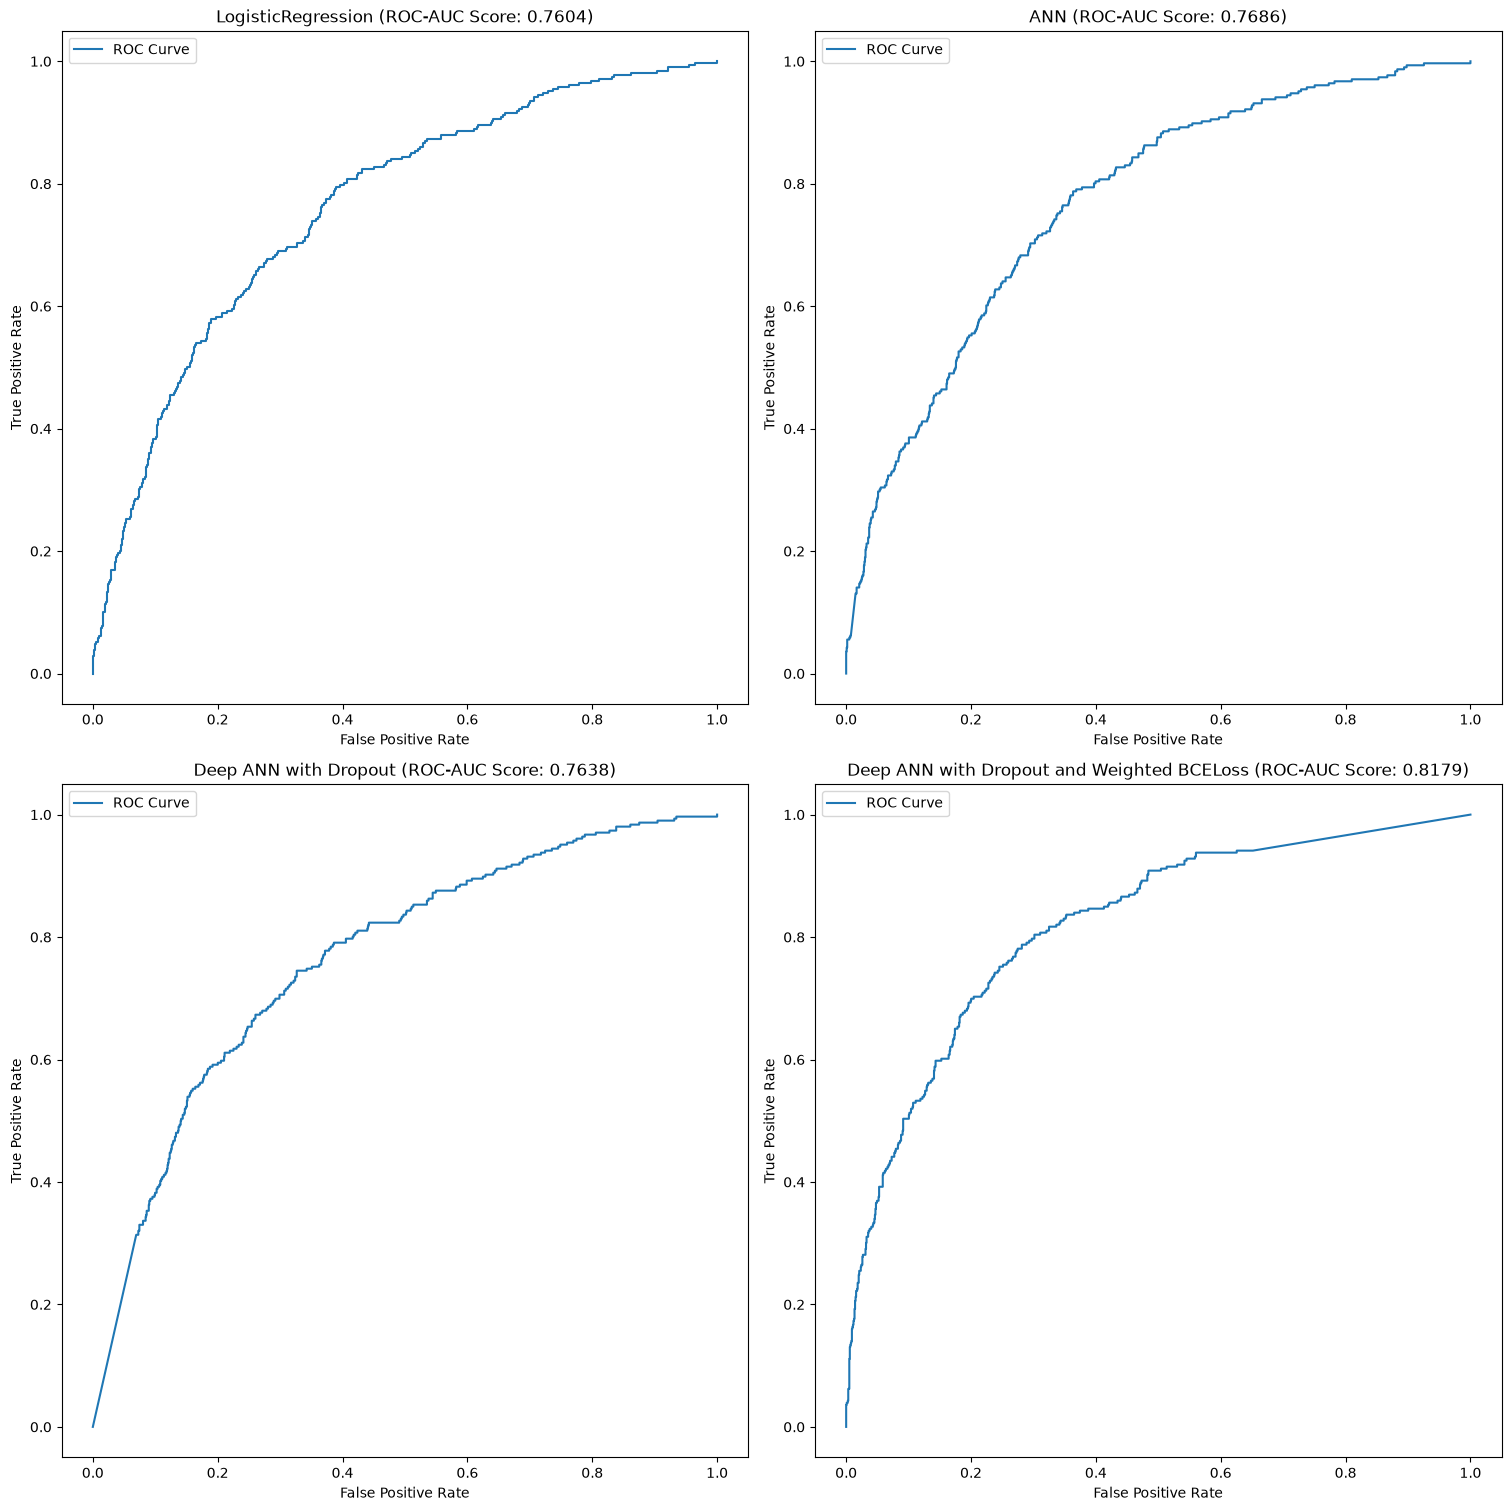

In [79]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(15, 15), layout="constrained")
ax = ax.flatten()

for i, (model_name, prob_output) in enumerate(zip(
    model_names, [logreg_prob, test_prob, test_prob_dropout, test_prob_imbalanced]
)):
    if isinstance(prob_output, list):
        prob_output = np.array(prob_output)
        
    if len(prob_output.shape) == 2:
        prob_output = prob_output[:, 1]

    curve = roc_curve(y_test, prob_output)
    fpr, tpr, _ = curve
    ax[i].plot(fpr, tpr, label="ROC Curve")
    ax[i].set_xlabel("False Positive Rate")
    ax[i].set_ylabel("True Positive Rate")
        
    ax[i].set_title(f"{model_name} (ROC-AUC Score: {roc_auc_score(y_test, prob_output):.4f})")
    ax[i].legend()
    
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

Dari hasil eksperimen yang dilakukan, model Logistic Regression dan ANN dengan 1 hidden layer mendominasi metrik akurasi, sedangkan metrik recall dan F1-score didominasi oleh ANN dengan 3 hidden layer, dropout layer, dan cost-sensitive learning. Metrik precision didominasi oleh ANN dengan 3 hidden layer dan dropout layer. Sementara itu, skor AUC-ROC didominasi oleh ANN dengan 3 hidden layer, dropout layer, dan cost-sensitive learning.

Model ANN dengan satu hidden layer mulai menunjukkan gejala overfitting setelah sekitar 50 epochs ketika training loss lebih kecil daripada validation loss, tetapi tidak terlalu signifikan. Model ANN dengan 3 hidden layer dan dropout layer menunjukkan gejala overfitting setelah sekitar 60 epochs ketika training loss kecil daripada validation loss, tetapi tidak terlalu signifikan. Model ANN dengan 3 hidden layer, dropout layer, dan cost-sensitive learning menunjukkan gejala overfitting di antara epoch ~20 dan ~80 ketika training accuracy lebih besar daripada validation accuracy, tetapi tidak terlalu signifikan.

Penambahan layer dan dropout membuat model dapat belajar pola lebih kompleks dengan risiko overfitting dan waktu training lebih lama. Penambahan class weight membuat model memberikan penalti lebih banyak ke class yang lebih langka, membuat model memprioritaskan class tersebut.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

Kesimpulan: ANN mampu mempelajari pola kompleks, tetapi sensitif terhadap struktur arsitektur, kompleksitas arsitektur, dan learning rate. Logistic Regression dapat melakukan prediksi secara cepat, tetapi menganggap data memiliki hubungan linear.

Saran: Learning rate scheduler